# Fashion-MNIST Image Classification: ANN vs CNN vs ResNet50

**Goal:** classify 28x28 grayscale clothing images into 10 classes and compare three model families, each tuned with the techniques that suit it.

| Model | Features|
|---|---|
| **ANN** | Wider layers, batch normalisation, dropout (rate chosen on validation data), early stopping, learning-rate scheduling |
| **CNN** | 3 convolutional blocks, batch normalisation, data augmentation, global average pooling, dropout, learning-rate scheduling |
| **ResNet50** | ImageNet preprocessing, frozen-backbone training, then fine-tuning of the top layers at a low learning rate |

**Method**
- 60,000 training images are split 90/10 (stratified) into train and validation; the 10,000 test images are held out.
- The best model is selected on **validation** accuracy. Test accuracy is only reported, never used to choose.
- All three models use the same data, seed and training recipe, so the comparison is fair.
- Every model takes `(28, 28, 1)` images scaled to 0-1.

**Contents:** 1. Setup, 2. Data, 3. Exploration, 4. Preprocessing, 5. Training helpers, 6. ANN, 7. CNN, 8. ResNet50, 9. Comparison, 10. Error analysis, 11. Save results, 12. Conclusions

## 1. Setup

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)

for folder in ["models", "results", "images"]:
    os.makedirs(folder, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: True


## 2. Load the data

Fashion-MNIST has 60,000 training and 10,000 test images (28x28, grayscale) in 10 clothing classes.

In [25]:
(X_train_original, y_train_original), (X_test_original, y_test_original) = (
    keras.datasets.fashion_mnist.load_data()
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

print("Training images:", X_train_original.shape)
print("Test images:    ", X_test_original.shape)
print("Image dtype:    ", X_train_original.dtype)
print("Pixel range:    ", X_train_original.min(), "to", X_train_original.max())
print("Missing values: ", np.isnan(X_train_original).sum() + np.isnan(X_test_original).sum())

Training images: (60000, 28, 28)
Test images:     (10000, 28, 28)
Image dtype:     uint8
Pixel range:     0 to 255
Missing values:  0


## 3. Exploratory data analysis

Looking at the images and the class balance before modelling.

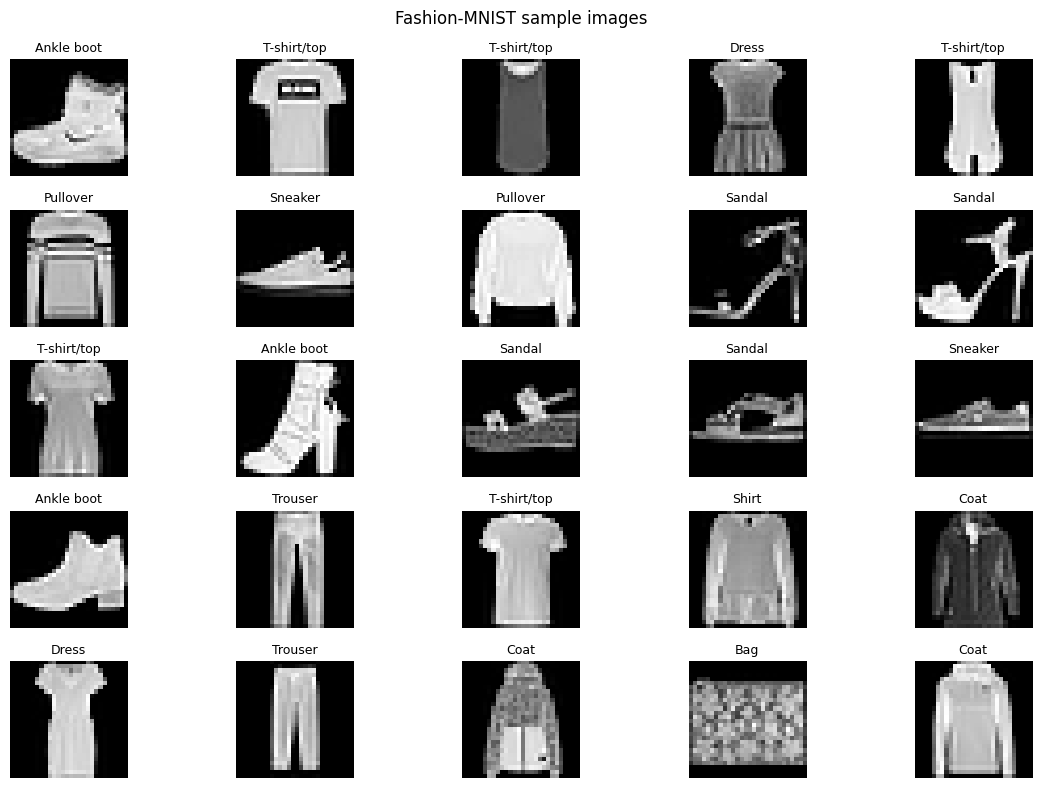

In [3]:
plt.figure(figsize=(12, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_original[i], cmap="gray")
    plt.title(class_names[y_train_original[i]], fontsize=9)
    plt.axis("off")
plt.suptitle("Fashion-MNIST sample images")
plt.tight_layout()
plt.show()

      Class  Count
T-shirt/top   6000
    Trouser   6000
   Pullover   6000
      Dress   6000
       Coat   6000
     Sandal   6000
      Shirt   6000
    Sneaker   6000
        Bag   6000
 Ankle boot   6000


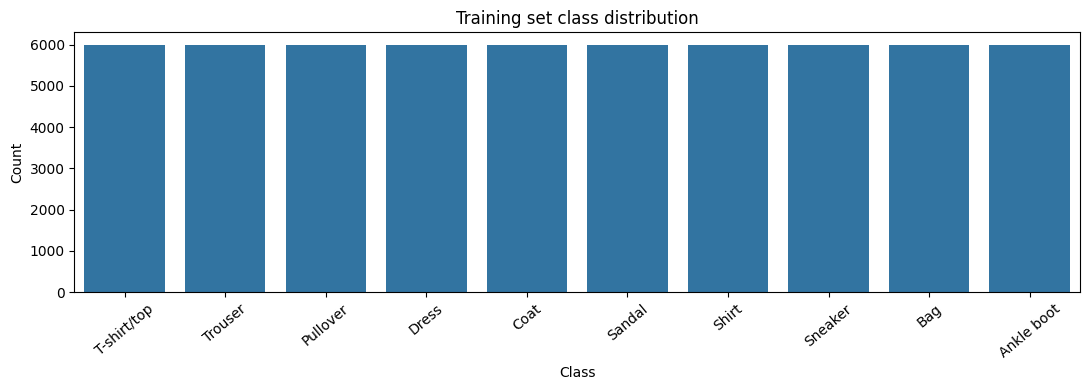

In [4]:
unique_labels, counts = np.unique(y_train_original, return_counts=True)
class_distribution = pd.DataFrame({
    "Class": [class_names[i] for i in unique_labels],
    "Count": counts,
})
print(class_distribution.to_string(index=False))

plt.figure(figsize=(11, 4))
sns.barplot(data=class_distribution, x="Class", y="Count")
plt.title("Training set class distribution")
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

**Observation:** the classes are perfectly balanced (6,000 images each), so plain accuracy is a fair metric and no class weighting is needed.
Shirt, T-shirt/top, Pullover and Coat look alike at this resolution, so I expect those to be the hardest classes.

## 4. Preprocessing

1. Scale pixels from 0-255 to 0-1.
2. Add a channel axis so images have shape `(28, 28, 1)`.
3. Create a stratified 90/10 train/validation split. The test set is left untouched.

In [5]:
X_train_all = X_train_original.astype("float32")[..., np.newaxis] / 255.0
X_test = X_test_original.astype("float32")[..., np.newaxis] / 255.0
y_train_all = y_train_original.copy()
y_test = y_test_original.copy()

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all,
    test_size=0.1, random_state=SEED, stratify=y_train_all,
)

print("Train:     ", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:      ", X_test.shape, y_test.shape)
print("Pixel range after scaling:", X_train.min(), "to", X_train.max())

Train:      (54000, 28, 28, 1) (54000,)
Validation: (6000, 28, 28, 1) (6000,)
Test:       (10000, 28, 28, 1) (10000,)
Pixel range after scaling: 0.0 to 1.0


## 5. Training helpers

One shared training recipe is used for every model: Adam optimiser, early stopping on validation loss (restoring the best weights), and a learning-rate reduction when validation loss stalls.
Results for the three final models are collected in `results` for the comparison later.

In [6]:
MODEL_NAMES = {
    "ann": "ANN",
    "cnn": "CNN",
    "resnet50": "ResNet50",
    "resnet50_stage1": "ResNet50 (frozen backbone)",
}

results = {}          # final models only: key -> metrics
histories = {}        # key -> training history
trained_models = {}   # final models only: key -> trained model


def compile_model(model, lr=1e-3):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def fit_model(model, epochs=30, batch_size=128, patience=5, lr_patience=2, verbose=2):
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=lr_patience, min_lr=1e-6
        ),
    ]
    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=batch_size,
        callbacks=callbacks, verbose=verbose,
    )
    return history, time.time() - start


def train_and_evaluate(key, model, record=True, verbose=2, **fit_kwargs):
    history, train_time = fit_model(model, verbose=verbose, **fit_kwargs)

    _, val_acc = model.evaluate(X_val, y_val, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    metrics = {
        "Model": MODEL_NAMES.get(key, key),
        "Key": key,
        "Val Accuracy (%)": round(val_acc * 100, 2),
        "Test Accuracy (%)": round(test_acc * 100, 2),
        "Test Loss": round(test_loss, 4),
        "Parameters": model.count_params(),
        "Train Time (s)": round(train_time),
    }
    histories[key] = history.history
    if record:
        results[key] = metrics
        trained_models[key] = model

    print(f"{metrics['Model']}: val acc {val_acc * 100:.2f}% | test acc {test_acc * 100:.2f}%")
    return metrics


def plot_history(key):
    h = histories[key]
    name = MODEL_NAMES.get(key, key)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, metric, label in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
        ax.plot(h[metric], label="Train")
        ax.plot(h["val_" + metric], label="Validation")
        ax.set_title(f"{name}: {label.lower()}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

## 6. ANN

A fully connected network on the flattened pixels. It ignores the 2D layout of the image, so it is the baseline the other models need to beat. I use layers of 512, 256 and 128 units with batch normalisation and dropout. Dropout does not always help a small network, so the rate is chosen on validation accuracy below, with 0.0 (no dropout) as one of the options.

In [7]:
def dense_block(units, dropout):
    return [
        layers.Dense(units, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout),
    ]


def build_ann(dropout=0.3):
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Flatten(),
        *dense_block(512, dropout),
        *dense_block(256, dropout),
        *dense_block(128, dropout / 2),
        layers.Dense(10, activation="softmax"),
    ])
    return compile_model(model)


build_ann(0.3).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 570,122 (2.17 MB)

 Trainable params: 568,330 (2.17 MB)

 Non-trainable params: 1,792 (7.00 KB)

### 6.1 Choosing the dropout rate (on validation data)

In [8]:
ann_tuning = []
for rate in [0.0, 0.2, 0.3]:
    keras.utils.set_random_seed(SEED)
    key = f"ann_dropout_{rate}"
    MODEL_NAMES[key] = f"ANN (dropout {rate})"
    metrics = train_and_evaluate(
        key, build_ann(rate), record=False, verbose=0, epochs=40, patience=6
    )
    ann_tuning.append({"Dropout rate": rate, "Val Accuracy (%)": metrics["Val Accuracy (%)"]})

ann_tuning = pd.DataFrame(ann_tuning)
best_rate = ann_tuning.loc[ann_tuning["Val Accuracy (%)"].idxmax(), "Dropout rate"]
print("\nBest dropout rate by validation accuracy:", best_rate)
ann_tuning

ANN (dropout 0.0): val acc 89.78% | test acc 88.32%
ANN (dropout 0.2): val acc 91.25% | test acc 90.43%
ANN (dropout 0.3): val acc 91.47% | test acc 90.33%

Best dropout rate by validation accuracy: 0.3


,Dropout rate,Val Accuracy (%)
0,0.0,89.78
1,0.2,91.25
2,0.3,91.47


### 6.2 Final ANN

Retrained with the chosen dropout rate.

Epoch 1/40
422/422 - 9s - 22ms/step - accuracy: 0.8046 - loss: 0.5536 - val_accuracy: 0.8420 - val_loss: 0.4199 - learning_rate: 0.0010
Epoch 2/40
422/422 - 1s - 3ms/step - accuracy: 0.8533 - loss: 0.4017 - val_accuracy: 0.8418 - val_loss: 0.4113 - learning_rate: 0.0010
Epoch 3/40
422/422 - 1s - 3ms/step - accuracy: 0.8680 - loss: 0.3626 - val_accuracy: 0.8633 - val_loss: 0.3654 - learning_rate: 0.0010
Epoch 4/40
422/422 - 1s - 3ms/step - accuracy: 0.8755 - loss: 0.3389 - val_accuracy: 0.8798 - val_loss: 0.3204 - learning_rate: 0.0010
Epoch 5/40
422/422 - 1s - 3ms/step - accuracy: 0.8832 - loss: 0.3154 - val_accuracy: 0.8493 - val_loss: 0.3955 - learning_rate: 0.0010
Epoch 6/40
422/422 - 1s - 3ms/step - accuracy: 0.8889 - loss: 0.3023 - val_accuracy: 0.8565 - val_loss: 0.3731 - learning_rate: 0.0010
Epoch 7/40
422/422 - 1s - 3ms/step - accuracy: 0.9003 - loss: 0.2703 - val_accuracy: 0.8922 - val_loss: 0.2913 - learning_rate: 5.0000e-04
Epoch 8/40
422/422 - 1s - 3ms/step - accuracy: 0.9

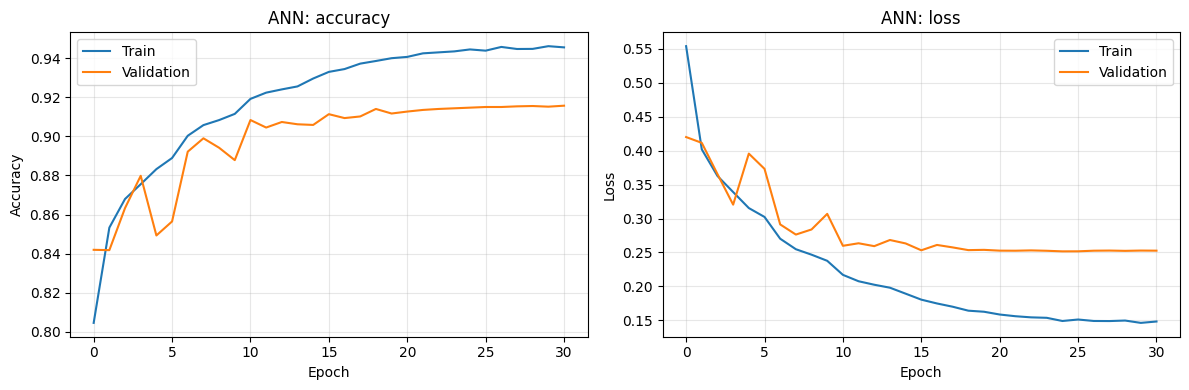

In [9]:
keras.utils.set_random_seed(SEED)
ann = build_ann(best_rate)
train_and_evaluate("ann", ann, epochs=40, patience=6)
plot_history("ann")

## 7. CNN


Convolutional layers look at small neighbourhoods of pixels, so they pick up edges, textures and shapes, which suits images better than a plain ANN. The CNN has three blocks of two 3x3 convolutions (32, 64 and 128 filters), each followed by batch normalisation, max pooling and dropout. Data augmentation (small shifts, rotations and horizontal flips) is applied only during training. Global average pooling replaces flattening to keep the parameter count low.

In [10]:
def conv_block(x, filters, dropout):
    for _ in range(2):
        x = layers.Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    return layers.Dropout(dropout)(x)


def build_cnn():
    inputs = keras.Input(shape=(28, 28, 1))

    # augmentation (only active during training)
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomTranslation(0.08, 0.08)(x)
    x = layers.RandomRotation(0.05)(x)

    x = conv_block(x, 32, 0.25)
    x = conv_block(x, 64, 0.25)
    x = conv_block(x, 128, 0.30)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="cnn")
    return compile_model(model)


keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 7, 7, 128)      │           51

 Total params: 305,578 (1.17 MB)

 Trainable params: 304,682 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/40
422/422 - 20s - 48ms/step - accuracy: 0.7107 - loss: 0.7896 - val_accuracy: 0.3093 - val_loss: 2.4163 - learning_rate: 0.0010
Epoch 2/40
422/422 - 14s - 34ms/step - accuracy: 0.8077 - loss: 0.5248 - val_accuracy: 0.8295 - val_loss: 0.4478 - learning_rate: 0.0010
Epoch 3/40
422/422 - 10s - 25ms/step - accuracy: 0.8324 - loss: 0.4594 - val_accuracy: 0.8710 - val_loss: 0.3431 - learning_rate: 0.0010
Epoch 4/40
422/422 - 11s - 25ms/step - accuracy: 0.8471 - loss: 0.4221 - val_accuracy: 0.8810 - val_loss: 0.3268 - learning_rate: 0.0010
Epoch 5/40
422/422 - 11s - 25ms/step - accuracy: 0.8565 - loss: 0.3958 - val_accuracy: 0.8860 - val_loss: 0.3076 - learning_rate: 0.0010
Epoch 6/40
422/422 - 10s - 25ms/step - accuracy: 0.8641 - loss: 0.3762 - val_accuracy: 0.8987 - val_loss: 0.2729 - learning_rate: 0.0010
Epoch 7/40
422/422 - 10s - 25ms/step - accuracy: 0.8686 - loss: 0.3629 - val_accuracy: 0.8898 - val_loss: 0.2962 - learning_rate: 0.0010
Epoch 8/40
422/422 - 10s - 25ms/step - ac

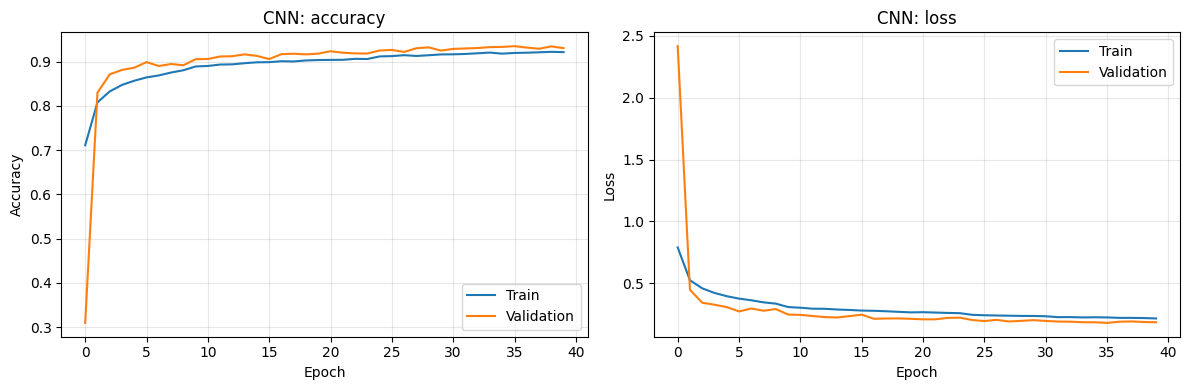

In [11]:
train_and_evaluate("cnn", cnn, epochs=40, patience=8, lr_patience=3)
plot_history("cnn")

## 8. ResNet50 (transfer learning)

ResNet50 pretrained on ImageNet is reused as a feature extractor. Fashion-MNIST images are small and grayscale, but ResNet50 expects larger colour images, so inside the model:

1. images are resized from 28x28 to 96x96,
2. the single channel is repeated to 3 channels,
3. pixels are scaled **back to 0-255** and the ImageNet channel means are subtracted.

**Training in two stages**
1. **Frozen backbone:** only the new classifier head is trained.
2. **Fine-tuning:** the top 25 ResNet layers are unfrozen and trained with a very small learning rate (1e-5), so the pretrained features can adapt to clothing images.

In [12]:
FINE_TUNE = True


def build_resnet50():
    base = keras.applications.ResNet50(
        weights="imagenet", include_top=False, input_shape=(96, 96, 3)
    )
    base.trainable = False

    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Resizing(96, 96)(inputs)
    x = layers.Concatenate()([x, x, x])      # grayscale -> 3 channels
    x = layers.Rescaling(255.0)(x)           # back to 0-255
    x = layers.Normalization(                # subtract ImageNet channel means
        mean=[103.939, 116.779, 123.68], variance=[1.0, 1.0, 1.0]
    )(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="resnet50_transfer")
    return compile_model(model), base


keras.utils.set_random_seed(SEED)
resnet_model, resnet_base = build_resnet50()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### 8.1 Stage 1: train the classifier head (backbone frozen)

Epoch 1/15
844/844 - 67s - 79ms/step - accuracy: 0.8187 - loss: 0.5185 - val_accuracy: 0.8723 - val_loss: 0.3403 - learning_rate: 0.0010
Epoch 2/15
844/844 - 41s - 49ms/step - accuracy: 0.8597 - loss: 0.3815 - val_accuracy: 0.8895 - val_loss: 0.3030 - learning_rate: 0.0010
Epoch 3/15
844/844 - 40s - 48ms/step - accuracy: 0.8722 - loss: 0.3468 - val_accuracy: 0.8873 - val_loss: 0.3015 - learning_rate: 0.0010
Epoch 4/15
844/844 - 41s - 49ms/step - accuracy: 0.8798 - loss: 0.3271 - val_accuracy: 0.8935 - val_loss: 0.2928 - learning_rate: 0.0010
Epoch 5/15
844/844 - 41s - 48ms/step - accuracy: 0.8848 - loss: 0.3090 - val_accuracy: 0.8965 - val_loss: 0.2820 - learning_rate: 0.0010
Epoch 6/15
844/844 - 40s - 48ms/step - accuracy: 0.8895 - loss: 0.2924 - val_accuracy: 0.8992 - val_loss: 0.2825 - learning_rate: 0.0010
Epoch 7/15
844/844 - 41s - 49ms/step - accuracy: 0.8954 - loss: 0.2842 - val_accuracy: 0.8988 - val_loss: 0.2812 - learning_rate: 0.0010
Epoch 8/15
844/844 - 41s - 49ms/step - ac

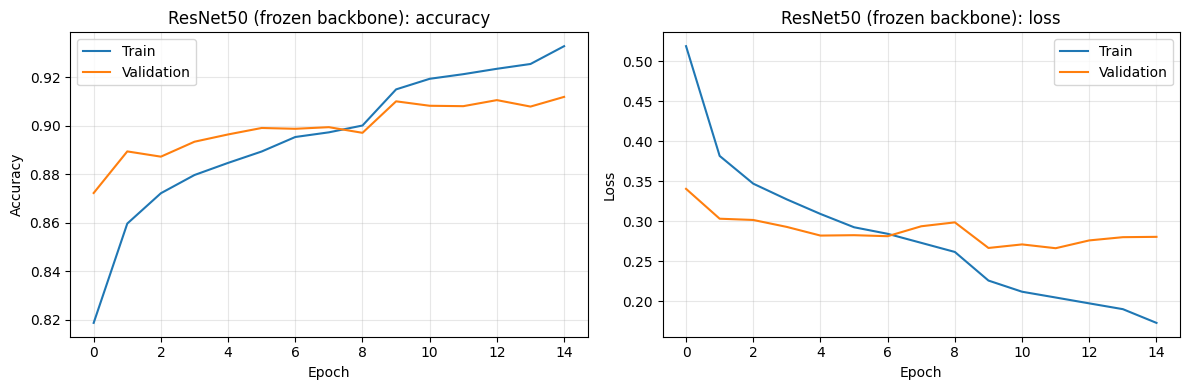

In [13]:
stage1 = train_and_evaluate(
    "resnet50_stage1", resnet_model,
    record=not FINE_TUNE,                 # if no fine-tuning, stage 1 is the final model
    epochs=15, batch_size=64, patience=3,
)
plot_history("resnet50_stage1")

### 8.2 Stage 2: fine-tune the top layers

Epoch 1/10
844/844 - 87s - 103ms/step - accuracy: 0.8842 - loss: 0.3300 - val_accuracy: 0.9038 - val_loss: 0.2751 - learning_rate: 1.0000e-05
Epoch 2/10
844/844 - 54s - 64ms/step - accuracy: 0.9194 - loss: 0.2133 - val_accuracy: 0.9093 - val_loss: 0.2631 - learning_rate: 1.0000e-05
Epoch 3/10
844/844 - 51s - 60ms/step - accuracy: 0.9387 - loss: 0.1636 - val_accuracy: 0.9133 - val_loss: 0.2636 - learning_rate: 1.0000e-05
Epoch 4/10
844/844 - 53s - 63ms/step - accuracy: 0.9541 - loss: 0.1253 - val_accuracy: 0.9150 - val_loss: 0.2676 - learning_rate: 1.0000e-05
Epoch 5/10
844/844 - 52s - 62ms/step - accuracy: 0.9677 - loss: 0.0921 - val_accuracy: 0.9160 - val_loss: 0.2759 - learning_rate: 5.0000e-06
ResNet50: val acc 90.93% | test acc 90.25%


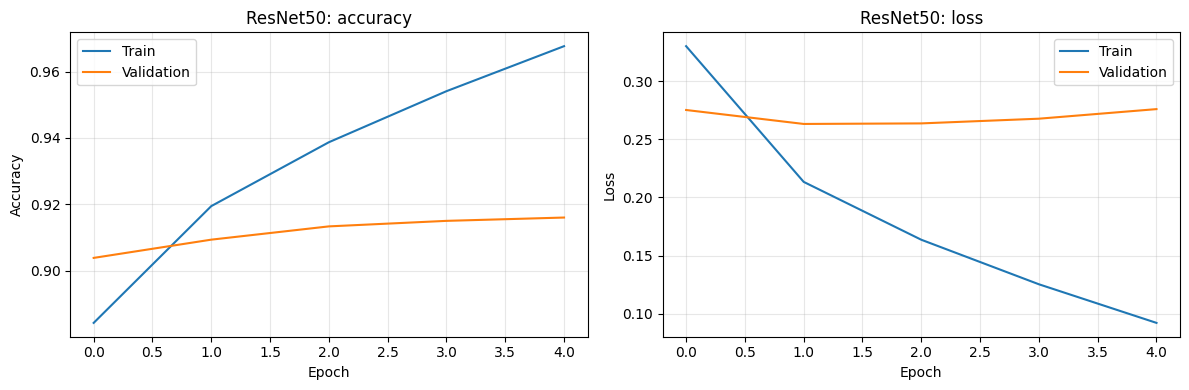

In [14]:
if FINE_TUNE:
    resnet_base.trainable = True
    for layer in resnet_base.layers[:-25]:
        layer.trainable = False

    compile_model(resnet_model, lr=1e-5)    # very small learning rate
    train_and_evaluate("resnet50", resnet_model, epochs=10, batch_size=64, patience=3)
    plot_history("resnet50")
else:
    results["resnet50"] = results.pop("resnet50_stage1")
    results["resnet50"].update({"Model": "ResNet50", "Key": "resnet50"})
    trained_models["resnet50"] = trained_models.pop("resnet50_stage1")
    print("Fine-tuning skipped; stage 1 is the final ResNet50 model.")

Fine-tuning gave only a small gain: validation accuracy went from 90.82% to 90.93% and test accuracy from 90.05% to 90.25%. Training accuracy kept climbing (to about 97%) while validation stayed around 91%, so the extra training mostly overfit.

### Robustness check with several seeds

A single run can be lucky or unlucky. Repeating the ANN and CNN with three different seeds gives a mean and standard deviation that are safer to quote.
ResNet50 is skipped because it is slow.

In [15]:
def multi_seed_test_accuracy(build_fn, seeds=(1, 2, 3), **fit_kwargs):
    accs = []
    for s in seeds:
        keras.utils.set_random_seed(s)
        model = build_fn()
        fit_model(model, verbose=0, **fit_kwargs)
        _, acc = model.evaluate(X_test, y_test, verbose=0)
        accs.append(acc * 100)
        print(f"  seed {s}: {acc * 100:.2f}%")
    return float(np.mean(accs)), float(np.std(accs))


multi_seed = {}
print("ANN"); multi_seed["ANN"] = multi_seed_test_accuracy(
    lambda: build_ann(best_rate), epochs=40, patience=6)
print("CNN"); multi_seed["CNN"] = multi_seed_test_accuracy(
    build_cnn, epochs=40, patience=8, lr_patience=3)

for name, (mean, std) in multi_seed.items():
    print(f"{name}: {mean:.2f}% +/- {std:.2f}%")

ANN
  seed 1: 90.14%
  seed 2: 90.32%
  seed 3: 90.26%
CNN
  seed 1: 92.28%
  seed 2: 92.62%
  seed 3: 92.55%
ANN: 90.24% +/- 0.07%
CNN: 92.48% +/- 0.15%


Mean test accuracy over three seeds: ANN 90.24 ± 0.07%, CNN 92.48 ± 0.15%. The CNN's lead holds across seeds.

## 9. Model comparison

The best model is chosen using **validation accuracy**. Test accuracy is shown for reporting only.

In [26]:
final_results = pd.DataFrame(results.values())

if FINE_TUNE:

    final_results.loc[final_results["Key"] == "resnet50", "Train Time (s)"] += stage1["Train Time (s)"]

final_results = final_results.sort_values("Val Accuracy (%)", ascending=False).reset_index(drop=True)

best_key = final_results.loc[0, "Key"]
print("Best model (by validation accuracy):", MODEL_NAMES[best_key])
final_results.drop(columns=["Key"])

Best model (by validation accuracy): CNN


,Model,Val Accuracy (%),Test Accuracy (%),Test Loss,Parameters,Train Time (s)
0,CNN,93.47,92.25,0.2059,305578,430
1,ANN,91.47,90.33,0.2965,570122,52
2,ResNet50,90.93,90.25,0.2857,23851274,1574


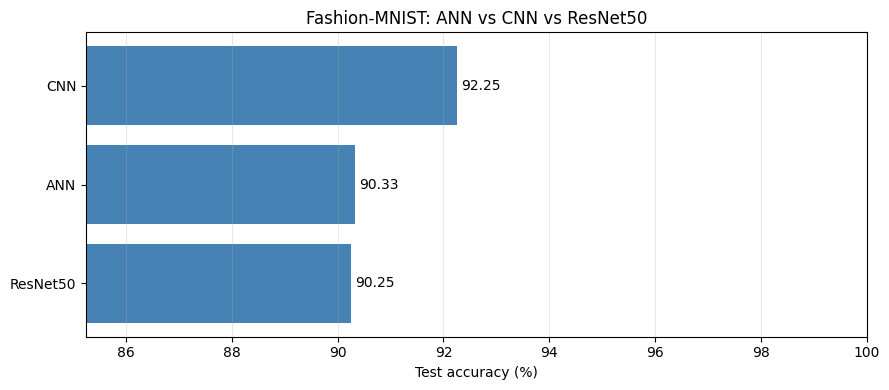

In [17]:
plot_df = final_results.sort_values("Test Accuracy (%)")

plt.figure(figsize=(9, 4))
bars = plt.barh(plot_df["Model"], plot_df["Test Accuracy (%)"], color="steelblue")
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.xlim(plot_df["Test Accuracy (%)"].min() - 5, 100)
plt.xlabel("Test accuracy (%)")
plt.title("Fashion-MNIST: ANN vs CNN vs ResNet50")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()



**Results**

- The CNN is the best model: 92.25% test accuracy against 90.33% for the ANN, about 1.9 points higher, and it uses fewer parameters (305k vs 570k).
- Tuning the dropout rate mattered for the ANN: validation accuracy was 89.78% with no dropout and 91.47% with 0.3.
- The fine-tuned ResNet50 reached 90.25%, below the CNN and about level with the ANN, even though it has 23.8 million parameters. ImageNet features are built for large colour photos, and upscaled 28x28 grayscale images look very different

## 10. Error analysis of the best model

Accuracy alone hides which classes the model gets wrong. The per-class report and confusion matrix show where it struggles.

In [18]:
best_model = trained_models[best_key]
y_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)

print(f"Best model: {MODEL_NAMES[best_key]}\n")
print(classification_report(y_test, y_pred, target_names=class_names))

Best model: CNN

              precision    recall  f1-score   support

 T-shirt/top       0.89      0.85      0.87      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.91      0.90      0.90      1000
       Dress       0.91      0.93      0.92      1000
        Coat       0.88      0.88      0.88      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.75      0.78      0.77      1000
     Sneaker       0.94      0.98      0.96      1000
         Bag       0.98      0.99      0.99      1000
  Ankle boot       0.98      0.95      0.96      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



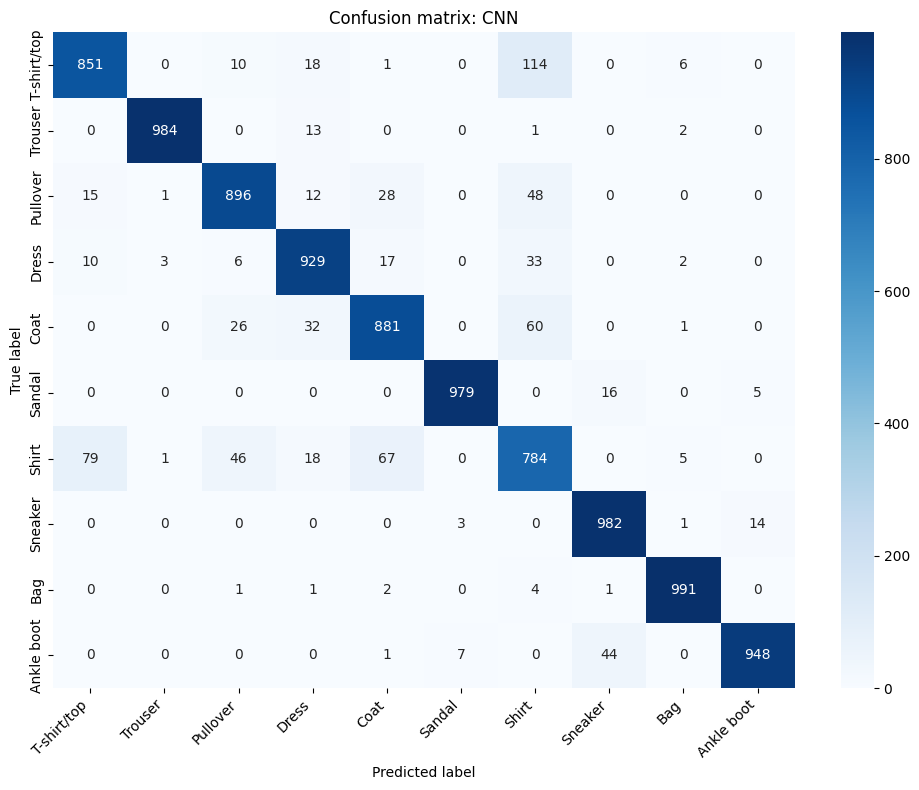

In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title(f"Confusion matrix: {MODEL_NAMES[best_key]}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("images/confusion_matrix_best.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# Which pairs of classes are confused most often?
off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)

pairs = [
    (class_names[i], class_names[j], off_diag[i, j])
    for i in range(10) for j in range(10) if off_diag[i, j] > 0
]
confusions = (
    pd.DataFrame(pairs, columns=["True class", "Predicted as", "Count"])
    .sort_values("Count", ascending=False)
    .head(8)
    .reset_index(drop=True)
)
confusions

,True class,Predicted as,Count
0,T-shirt/top,Shirt,114
1,Shirt,T-shirt/top,79
2,Shirt,Coat,67
3,Coat,Shirt,60
4,Pullover,Shirt,48
5,Shirt,Pullover,46
6,Ankle boot,Sneaker,44
7,Dress,Shirt,33


Misclassified test images: 775 of 10000


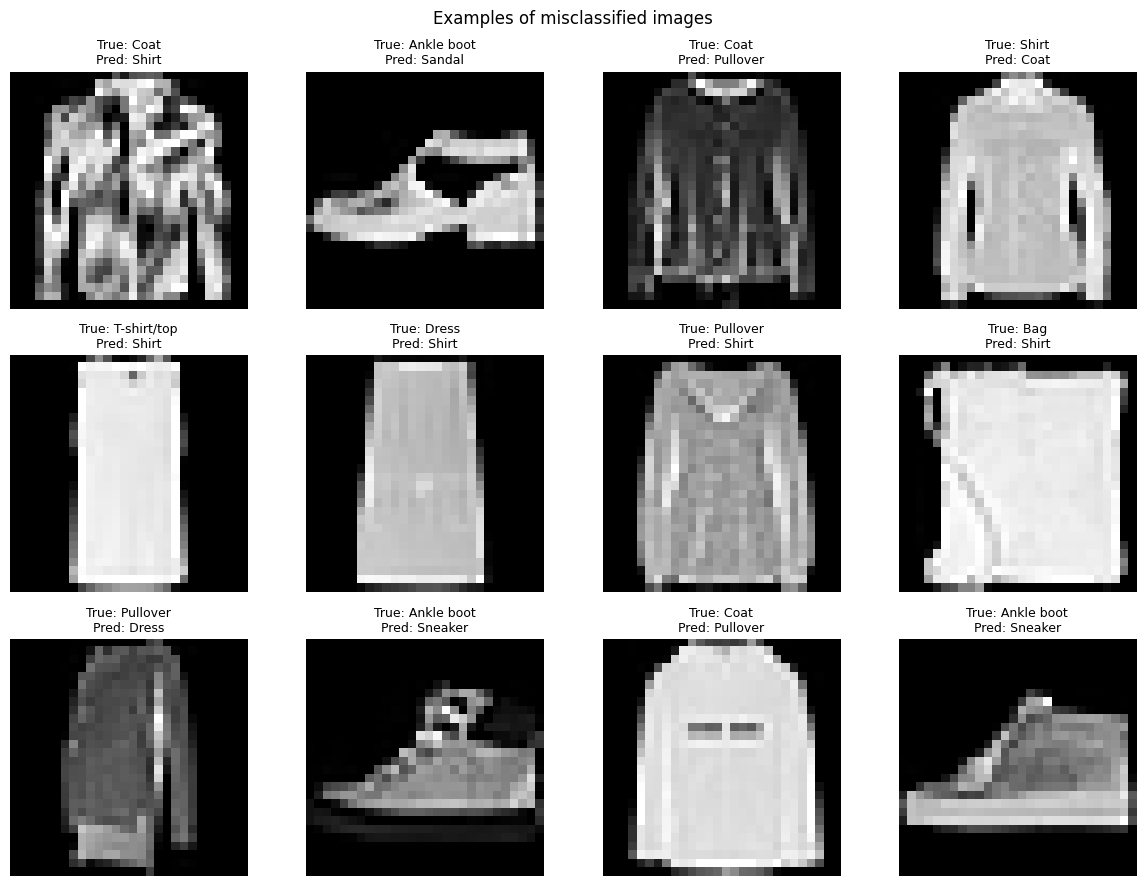

In [21]:
wrong_indices = np.where(y_pred != y_test)[0]
print("Misclassified test images:", len(wrong_indices), "of", len(y_test))

plt.figure(figsize=(12, 9))
for i, idx in enumerate(wrong_indices[:12]):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=9)
    plt.axis("off")
plt.suptitle("Examples of misclassified images")
plt.tight_layout()
plt.savefig("images/misclassified_examples.png", dpi=150, bbox_inches="tight")
plt.show()

**What the errors show**

- Shirt has the lowest F1 score (0.77), followed by T-shirt/top (0.87) and Coat (0.88). Trouser, Sandal and Bag are the easiest classes, all at about 0.98 or higher.
- The most common mistake is T-shirt/top predicted as Shirt (114 images), then Shirt predicted as T-shirt/top (79) and Shirt predicted as Coat (67). Ankle boot is sometimes predicted as Sneaker (44).
- At 28x28 resolution these tops have very similar outlines. The details that separate them, such as collars, buttons and sleeve length, are only a few pixels wide.

## 11. Save results and models

In [22]:
final_results.to_csv("results/model_comparison.csv", index=False)

for key, model in trained_models.items():
    if key.startswith("resnet50"):
        continue
    model.save(f"models/{key}.keras")

print("Saved results/model_comparison.csv")
print("Saved models:", [f for f in os.listdir("models") if f.endswith(".keras")])

Saved results/model_comparison.csv
Saved models: ['ann.keras', 'cnn.keras']


In [23]:
# Only runs in Google Colab: download outputs to your computer
try:
    from google.colab import files
    files.download("results/model_comparison.csv")
    for f in os.listdir("models"):
        if f.endswith(".keras"):
            files.download(f"models/{f}")
except ImportError:
    print("Not running in Colab. Files are in the models/ and results/ folders.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusions

- **Best model:** the CNN, with 92.25% test accuracy (92.48 ± 0.15% over three seeds), about 2 points above the ANN (90.33%).
- **Architecture:** the CNN beat the ANN while using fewer parameters (305k vs 570k), because convolutions use the 2D structure of the image and the ANN does not.
- **What helped:** dropout at 0.3 gave the best validation accuracy for the ANN (91.47%, against 89.78% with no dropout). Batch normalisation and data augmentation made the CNN train more stably.
- **Transfer learning:** the fine-tuned ResNet50 reached 90.25%, below the CNN. Fine-tuning added only about 0.2 points and the model overfit. A likely reason is that ImageNet features do not suit small 28x28 grayscale images that are scaled up.
- **Hardest classes:** Shirt (F1 0.77) was the hardest, mostly confused with T-shirt/top, Coat and Pullover, because the differences between them are tiny at this resolution.

**Next steps:** try a deeper CNN, stronger augmentation, or an ensemble of the best models.